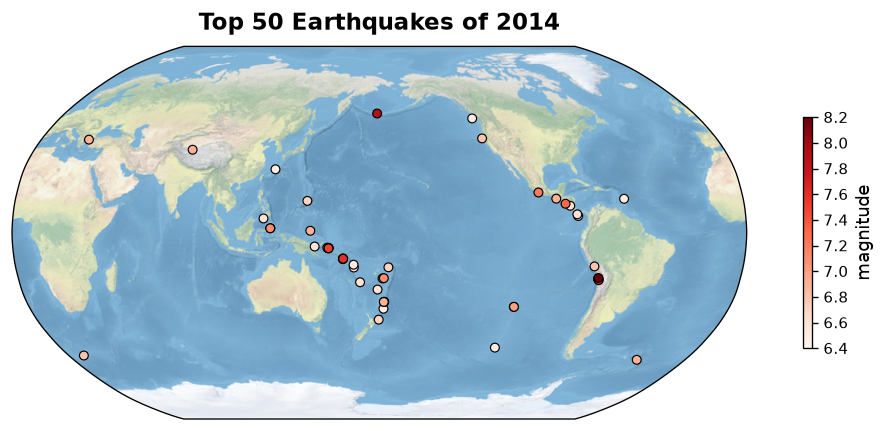

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# 1. 读取数据
df = pd.read_csv("usgs_earthquakes.csv")

# 转换时间和数值类型
df["time"] = pd.to_datetime(df["time"], errors="coerce")

for col in ["latitude", "longitude", "mag"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2. 筛选2014年有效数据
earthquakes = df.loc[
    df["time"].dt.year == 2014
].dropna(subset=["latitude", "longitude", "mag"])

# 选择震级最大的50次地震
top50 = earthquakes.nlargest(50, "mag").copy()

# 小震级先画，大震级后画，减少遮挡
plot_data = top50.sort_values("mag")

# 3. 创建地图
fig = plt.figure(figsize=(10, 5), dpi=120)

# Robinson投影，以180°经线为中心
ax = fig.add_subplot(
    1, 1, 1,
    projection=ccrs.Robinson(central_longitude=180)
)

ax.set_global()

# 地球影像底图，需要scipy支持影像投影转换
ax.stock_img()

# 4. 绘制地震位置
scatter = ax.scatter(
    plot_data["longitude"],
    plot_data["latitude"],
    c=plot_data["mag"],
    s=28,
    cmap="Reds",
    vmin=6.4,
    vmax=8.2,
    edgecolors="black",
    linewidths=0.7,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# 5. 添加标题
ax.set_title(
    "Top 50 Earthquakes of 2014",
    fontsize=14,
    fontweight="bold",
    pad=10
)

# 6. 添加颜色条
cbar = fig.colorbar(
    scatter,
    ax=ax,
    orientation="vertical",
    shrink=0.5,
    pad=0.06,
    aspect=25
)

cbar.set_label("magnitude", fontsize=11)
cbar.set_ticks(np.arange(6.4, 8.21, 0.2))
cbar.ax.tick_params(labelsize=9)

# 7. 保存并显示图片
fig.savefig(
    "PS4_Q1_Global_Earthquakes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


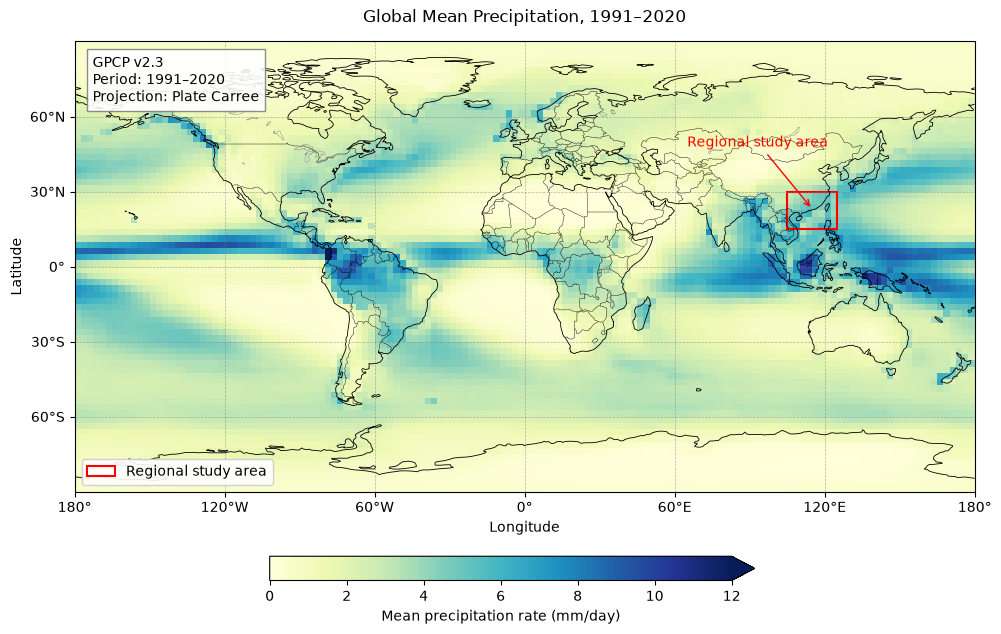

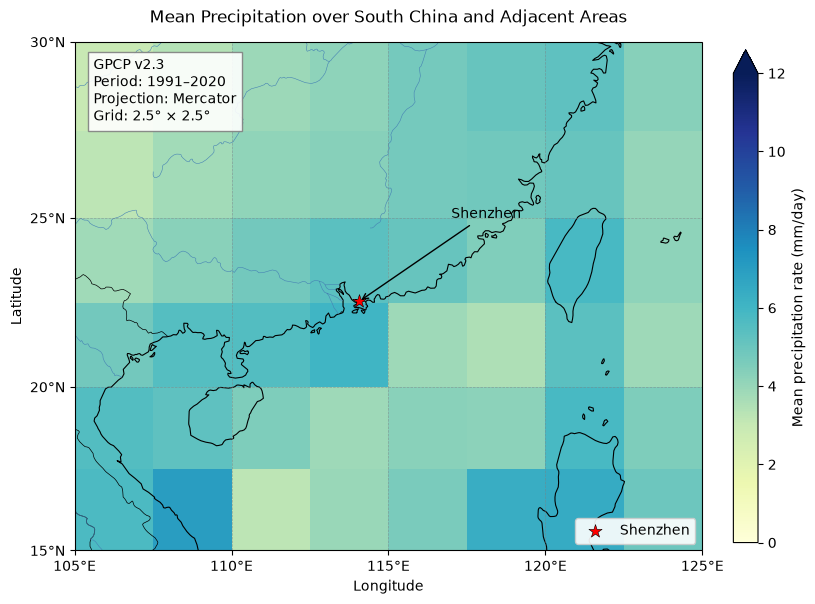

In [3]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

# 读取数据，跳过格式有问题的时间边界变量
path = r"C:\Users\a3026\precip.mon.mean.nc"
ds = xr.open_dataset(path, drop_variables=["time_bnds"])
rain = ds["precip"]

# 经度统一为 -180～180，并计算1991—2020年平均值
rain = rain.assign_coords(
    lon=((rain.lon + 180) % 360) - 180
).sortby("lon").sortby("lat")

rain_mean = rain.sel(time=slice("1991-01-01", "2020-12-31")).mean("time")

data_crs = ccrs.PlateCarree()
plt.rcParams["font.size"] = 10

# 2.1 全球地图：Plate Carrée投影
fig = plt.figure(figsize=(13, 7))
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
ax.set_global()

im = ax.pcolormesh(
    rain_mean.lon, rain_mean.lat, rain_mean,
    transform=data_crs, cmap="YlGnBu",
    shading="auto", vmin=0, vmax=12
)

ax.coastlines(linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)
ax.add_feature(cfeature.LAKES, facecolor="none",
               edgecolor="gray", linewidth=0.3)

ax.set_xticks(np.arange(-180, 181, 60), crs=data_crs)
ax.set_yticks(np.arange(-60, 61, 30), crs=data_crs)
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.gridlines(
    crs=data_crs, xlocs=np.arange(-180, 181, 60),
    ylocs=np.arange(-60, 61, 30),
    linewidth=0.5, color="gray", alpha=0.6, linestyle="--"
)

# 标出下一幅图的研究区域
box = mpatches.Rectangle(
    (105, 15), 20, 15, transform=data_crs,
    fill=False, edgecolor="red", linewidth=1.5,
    label="Regional study area"
)
ax.add_patch(box)
ax.legend(loc="lower left", framealpha=0.9)

ax.annotate(
    "Regional study area",
    xy=(115, 23), xycoords=data_crs._as_mpl_transform(ax),
    xytext=(65, 48), textcoords=data_crs._as_mpl_transform(ax),
    arrowprops=dict(arrowstyle="->", color="red"),
    color="red", fontsize=10
)

ax.text(
    0.02, 0.97,
    "GPCP v2.3\nPeriod: 1991–2020\nProjection: Plate Carree",
    transform=ax.transAxes, va="top",
    bbox=dict(facecolor="white", edgecolor="gray", alpha=0.9)
)
ax.set_title("Global Mean Precipitation, 1991–2020", pad=14)

cbar = fig.colorbar(
    im, ax=ax, orientation="horizontal",
    pad=0.12, fraction=0.045, extend="max"
)
cbar.set_label("Mean precipitation rate (mm/day)")
fig.savefig("PS4_2_1_global.png", dpi=300, bbox_inches="tight")
plt.show()

# 2.2 区域地图：Mercator投影
region = rain_mean.sel(lon=slice(105, 125), lat=slice(15, 30))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection=ccrs.Mercator())
ax.set_extent([105, 125, 15, 30], crs=data_crs)

im = ax.pcolormesh(
    region.lon, region.lat, region,
    transform=data_crs, cmap="YlGnBu",
    shading="auto", vmin=0, vmax=12
)

ax.coastlines(resolution="50m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
ax.add_feature(cfeature.RIVERS.with_scale("50m"),
               edgecolor="steelblue", linewidth=0.4)

ax.set_xticks(np.arange(105, 126, 5), crs=data_crs)
ax.set_yticks(np.arange(15, 31, 5), crs=data_crs)
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.gridlines(
    crs=data_crs, xlocs=np.arange(105, 126, 5),
    ylocs=np.arange(15, 31, 5),
    linewidth=0.5, color="gray", alpha=0.6, linestyle="--"
)

# 标注深圳的位置
ax.scatter(
    114.06, 22.55, transform=data_crs,
    color="red", marker="*", s=100,
    edgecolors="black", linewidths=0.4,
    label="Shenzhen", zorder=5
)
ax.annotate(
    "Shenzhen",
    xy=(114.06, 22.55), xycoords=data_crs._as_mpl_transform(ax),
    xytext=(117, 25), textcoords=data_crs._as_mpl_transform(ax),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10
)
ax.legend(loc="lower right", framealpha=0.9)

ax.text(
    0.03, 0.97,
    "GPCP v2.3\nPeriod: 1991–2020\nProjection: Mercator\nGrid: 2.5° × 2.5°",
    transform=ax.transAxes, va="top",
    bbox=dict(facecolor="white", edgecolor="gray", alpha=0.9)
)
ax.set_title(
    "Mean Precipitation over South China and Adjacent Areas",
    pad=14
)

cbar = fig.colorbar(im, ax=ax, pad=0.04, shrink=0.8, extend="max")
cbar.set_label("Mean precipitation rate (mm/day)")
fig.savefig("PS4_2_2_regional.png", dpi=300, bbox_inches="tight")
plt.show()